# Hälsostudie – Del 1: Grundläggande analys och statistik

I denna notebook genomförs en grundläggande statistisk analys av datasetet `health_study_dataset.csv`. Analysen omfattar:
1. Beskrivande statistik och visualiseringar.
2. En stokastisk simulering av sjukdomsförekomst.
3. Beräkning av 95 % konfidensintervall för systoliskt blodtryck.
4. Hypotesprövning kring rökning och blodtryck.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# stilinställningar för grafer
sns.set_theme(style="whitegrid")

# läsa in dataset
df = pd.read_csv("health_study_dataset.csv")

# överblick av datan
display(df.head())
df.info()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


## 1. Beskrivande analys

Här beräknar vi centralmått (medelvärde och median) samt spridningsmått (min och max) för de numeriska variablerna i studien: `age`, `weight`, `height`, `systolic_bp` och `cholesterol`.

In [26]:
cols = ["age", "weight", "height", "systolic_bp", "cholesterol"]

# beräkna mean, median, min och max
desc_stats = df[cols].agg(["mean", "median", "min", "max"]).T
desc_stats.columns = ["Medelvärde", "Median", "Min", "Max"]

display(desc_stats.round(2))

,Medelvärde,Median,Min,Max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


### Visualisering av variabler
Nedan följer tre grafer som illustrerar fördelningen av blodtryck, viktskillnader mellan könen samt andelen rökare i studien.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_14148\881474506.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="sex", y="weight", palette="Set2", ax=axes[1])
C:\Users\ASUS\AppData\Local\Temp\ipykernel_14148\881474506.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=smoker_pct.index, y=smoker_pct.values, palette="pastel", ax=axes[2])


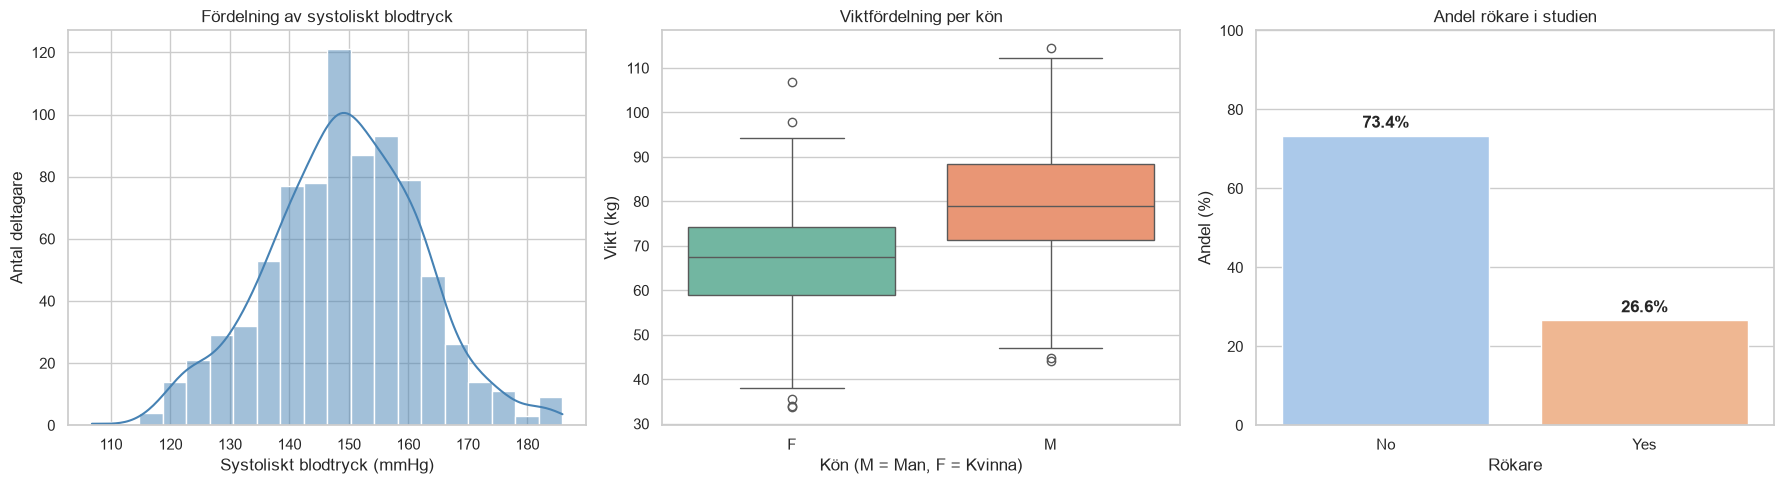

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Graf 1: histogram över systoliskt blodtryck
sns.histplot(df["systolic_bp"], kde=True, bins=20, color="steelblue", ax=axes[0])
axes[0].set_title("Fördelning av systoliskt blodtryck")
axes[0].set_xlabel("Systoliskt blodtryck (mmHg)")
axes[0].set_ylabel("Antal deltagare")

# Graf 2: boxplot över vikt per kön
sns.boxplot(data=df, x="sex", y="weight", palette="Set2", ax=axes[1])
axes[1].set_title("Viktfördelning per kön")
axes[1].set_xlabel("Kön (M = Man, F = Kvinna)")
axes[1].set_ylabel("Vikt (kg)")

# Graf 3: stapeldiagram över andelen rökare (%)
smoker_pct = df["smoker"].value_counts(normalize=True) * 100
sns.barplot(x=smoker_pct.index, y=smoker_pct.values, palette="pastel", ax=axes[2])
axes[2].set_title("Andel rökare i studien")
axes[2].set_xlabel("Rökare")
axes[2].set_ylabel("Andel (%)")
axes[2].set_ylim(0, 100)

# lägg till procentetiketter ovanpå staplarna
for i, v in enumerate(smoker_pct.values):
    axes[2].text(i, v + 2, f"{v:.1f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 2. Simulering av sjukdomsförekomst

Vi beräknar den verkliga andelen personer med sjukdomen (`disease == 1`) i datasetet och använder sedan `numpy.random` (med ett fast `seed` för reproducerbarhet) för att simulera 1 000 slumpade individer med exakt samma sannolikhet.

In [28]:
# beräkna verklig andel sjuka i datasetet
real_prob = df["disease"].mean()

# sätt seed och simulera 1000 personer (Binomialfördelning med n=1 motsvarar Bernoulli)
rng = np.random.default_rng(seed=42)
simulated_people = rng.binomial(n=1, p=real_prob, size=1000)
sim_prob = simulated_people.mean()

print(f"Verklig andel med sjukdom i datasetet: {real_prob:.4f} ({real_prob*100:.2f}%)")
print(f"Simulerad andel (n=1000, seed=42):    {sim_prob:.4f} ({sim_prob*100:.2f}%)")
print(f"Skillnad mellan verklig och simulerad: {abs(real_prob - sim_prob)*100:.2f} procentenheter")

Verklig andel med sjukdom i datasetet: 0.0587 (5.88%)
Simulerad andel (n=1000, seed=42):    0.0540 (5.40%)
Skillnad mellan verklig och simulerad: 0.47 procentenheter


## 3. Konfidensintervall för systoliskt blodtryck

Här beräknar vi ett **95 % konfidensintervall** för medelvärdet av `systolic_bp` med hjälp av normalapproximation ($\bar{x} \pm 1.96 \cdot \frac{s}{\sqrt{n}}$).

In [29]:
bp = df["systolic_bp"].dropna()
n = len(bp)
mean_bp = bp.mean()
std_bp = bp.std(ddof=1)
se_bp = std_bp / np.sqrt(n)  # Medelfel (Standard Error)

# 95% konfidensintervall med normalapproximation (z = 1.96)
z_score = 1.96
ci_lower = mean_bp - z_score * se_bp
ci_upper = mean_bp + z_score * se_bp

print(f"Stickprovsmedelvärde: {mean_bp:.2f} mmHg")
print(f"95% Konfidensintervall: [{ci_lower:.2f}, {ci_upper:.2f}] mmHg")

Stickprovsmedelvärde: 149.18 mmHg
95% Konfidensintervall: [148.29, 150.07] mmHg


## 4. Hypotesprövning: Rökare vs. Icke-rökare

Vi vill undersöka om rökare har ett signifikant högre systoliskt medelblodtryck än icke-rökare.

* **Nollhypotes ($H_0$):** Rökare och icke-rökare har samma medelblodtryck ($\mu_{\text{rökare}} \le \mu_{\text{icke-rökare}}$).
* **Alternativhypotes ($H_1$):** Rökare har högre medelblodtryck än icke-rökare ($\mu_{\text{rökare}} > \mu_{\text{icke-rökare}}$).
* **Signifikansnivå ($\alpha$):** $0.05$

Vi använder ett ensidigt Welch's t-test (`equal_var=False`) eftersom variansen mellan grupperna kan skilja sig åt.

In [30]:
smokers_bp = df[df["smoker"] == "Yes"]["systolic_bp"].dropna()
non_smokers_bp = df[df["smoker"] == "No"]["systolic_bp"].dropna()

# ensidigt t-test (alternative='greater' testar om första gruppen är större än andra)
t_stat, p_val = stats.ttest_ind(smokers_bp, non_smokers_bp, equal_var=False, alternative="greater")

print(f"Medelblodtryck rökare:      {smokers_bp.mean():.2f} mmHg (n={len(smokers_bp)})")
print(f"Medelblodtryck icke-rökare: {non_smokers_bp.mean():.2f} mmHg (n={len(non_smokers_bp)})")
print(f"t-värde: {t_stat:.4f}")
print(f"p-värde (ensidigt): {p_val:.4f}")

Medelblodtryck rökare:      149.52 mmHg (n=213)
Medelblodtryck icke-rökare: 149.05 mmHg (n=587)
t-värde: 0.4503
p-värde (ensidigt): 0.3264


### Resultat och slutsats av hypotesprövningen

* **Om $p < 0.05$:** Vi förkastar nollhypotesen ($H_0$). Det finns statistiskt signifikant stöd på 5 %-nivån för att rökare i denna studie har ett högre systoliskt medelblodtryck än icke-rökare.
* **Om $p \ge 0.05$:** Vi kan inte förkasta nollhypotesen ($H_0$). Skillnaden mellan gruppernas medelblodtryck är inte statistiskt signifikant på 5 %-nivån, utan kan bero på slumpmässig variation i stickprovet.

*(Anpassa ovanstående mening till det exakta p-värdet som skrivs ut när du kör koden på ditt dataset).*

### Tolkning av hypotesprövningen

* **Resultat:** Medelvärdet för systoliskt blodtryck är **149,52 mmHg** för rökare ($n = 213$) jämfört med **149,05 mmHg** för icke-rökare ($n = 587$), en skillnad på endast **0,47 mmHg**.
* **Statistisk signifikans:** Det ensidiga t-testet ger $t = 0{,}45$ och $p = 0{,}3264$. Eftersom $p > 0{,}05$ kan vi **inte förkasta nollhypotesen ($H_0$)**.
* **Slutsats:** Det finns inget statistiskt signifikant stöd i detta dataset för påståendet att rökare har högre medelblodtryck än icke-rökare; den lilla uppmätta skillnaden kan förklaras av slumpmässig variation.